# 05 – Day-Ahead-Preisprognose

**Fragestellung:** Wie gut lässt sich der stündliche Day-Ahead-Preis mit
Fundamentaldaten (Wind, Solar, Last) und vergangenen Preisen vorhersagen?

### Realistisches Prognose-Setup

Die Day-Ahead-Auktion für Tag *D* schließt am Mittag von Tag *D−1*. Zu diesem
Zeitpunkt kennt man alle Preise bis einschließlich *D−1*, aber **keinen Preis von
Tag *D***. Deshalb:

* `price_lag_1` (Preis der Vorstunde) wäre ein **Informationsleck** → nicht verwendet
* zulässig: `price_lag_24`, `price_lag_168`, Kennzahlen des Vortags
* Wind, Solar und Last: Ist-Werte als Näherung für die Prognosen, die am Vortag
  verfügbar sind (*perfect-foresight*-Annahme → die Ergebnisse sind eine Obergrenze)

**Validierung:** zeitlicher Split – Training 2023–2024, Test 2025 (out-of-sample).

In [1]:
import sys
from pathlib import Path

# Projektpaket importierbar machen (alternativ: pip install -e .)
sys.path.insert(0, str(Path.cwd().parent / "src"))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

from energy_analytics.database import load_energy_data
from energy_analytics.modeling import MODEL_FEATURES, TARGET, add_forecast_features, evaluate, time_split
from energy_analytics.plotting import COLORS, TEXT_MUTED, save, set_style

set_style()
df = add_forecast_features(load_energy_data())
train, test = time_split(df, "2025-01-01")
print(f"Training: {len(train):,} Stunden  |  Test: {len(test):,} Stunden")
print("Features:", MODEL_FEATURES)

Training: 17,497 Stunden  |  Test: 8,760 Stunden
Features: ['hour', 'day_of_week', 'month', 'is_weekend', 'wind', 'solar', 'load', 'residual_load', 'renewable_share_pct', 'price_lag_24', 'price_lag_168', 'price_prev_day_mean', 'price_prev_day_std']


## Modelle

1. **Naiv (Vortag):** Preis = Preis derselben Stunde am Vortag
2. **Naiv (Vorwoche):** Preis = Preis derselben Stunde vor 7 Tagen
3. **Lineare Regression** auf allen Features
4. **XGBoost** (Gradient Boosting) – kann die nichtlineare Merit-Order abbilden

Die Hyperparameter von XGBoost sind bewusst konservativ gewählt und wurden
**nicht** auf dem Testjahr optimiert.

In [3]:
X_train, y_train = train[MODEL_FEATURES], train[TARGET]
X_test, y_test = test[MODEL_FEATURES], test[TARGET]

linreg = LinearRegression().fit(X_train, y_train)
xgb = XGBRegressor(
    n_estimators=600, learning_rate=0.03, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42,
).fit(X_train, y_train)

predictions = {
    "Naiv (Vortag)": test["price_lag_24"],
    "Naiv (Vorwoche)": test["price_lag_168"],
    "Lineare Regression": linreg.predict(X_test),
    "XGBoost": xgb.predict(X_test),
}
results = pd.DataFrame({name: evaluate(y_test, pred) for name, pred in predictions.items()}).T
results["Verbesserung ggü. Naiv (Vortag)"] = (1 - results["MAE"] / results.loc["Naiv (Vortag)", "MAE"]).map("{:+.0%}".format)
results.round(2)

,MAE,RMSE,Bias,Verbesserung ggü. Naiv (Vortag)
Naiv (Vortag),25.97,40.45,-0.07,+0%
Naiv (Vorwoche),32.83,49.33,0.22,-26%
Lineare Regression,15.96,23.71,-1.72,+39%
XGBoost,15.21,23.22,-2.44,+41%


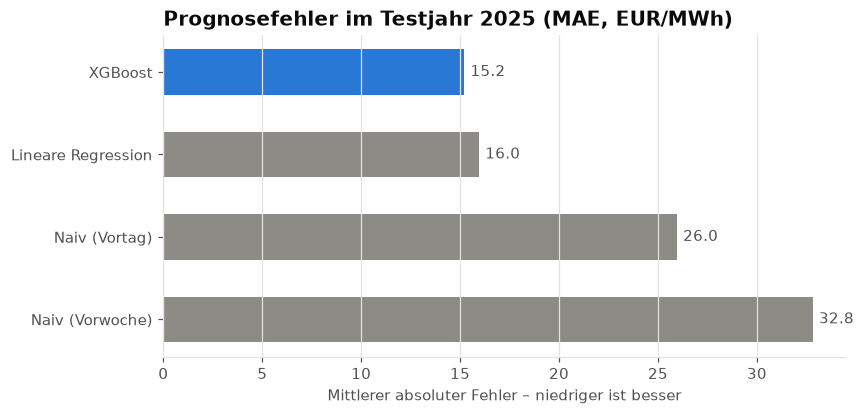

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = results.sort_values("MAE", ascending=False)
colors = [COLORS["blue"] if n == "XGBoost" else COLORS["grey"] for n in order.index]
bars = ax.barh(order.index, order["MAE"], color=colors, height=0.55)
ax.bar_label(bars, fmt="%.1f", padding=4, color=TEXT_MUTED)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Prognosefehler im Testjahr 2025 (MAE, EUR/MWh)")
ax.set_xlabel("Mittlerer absoluter Fehler – niedriger ist besser")
save(fig, "model_comparison")
plt.show()

## Beispielwoche

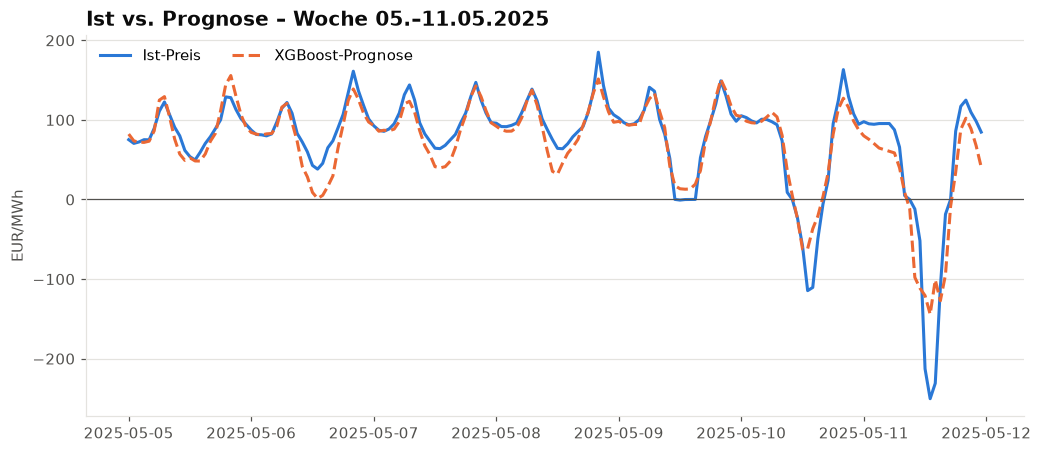

In [5]:
week = test.assign(pred=predictions["XGBoost"])
week = week[(week["timestamp_local"] >= "2025-05-05") & (week["timestamp_local"] < "2025-05-12")]

fig, ax = plt.subplots()
ax.plot(week["timestamp_local"], week["price"], color=COLORS["blue"], label="Ist-Preis")
ax.plot(week["timestamp_local"], week["pred"], color=COLORS["orange"], linestyle="--", label="XGBoost-Prognose")
ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_title("Ist vs. Prognose – Woche 05.–11.05.2025")
ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper left", ncol=2)
save(fig, "forecast_example_week")
plt.show()

## Fehleranalyse

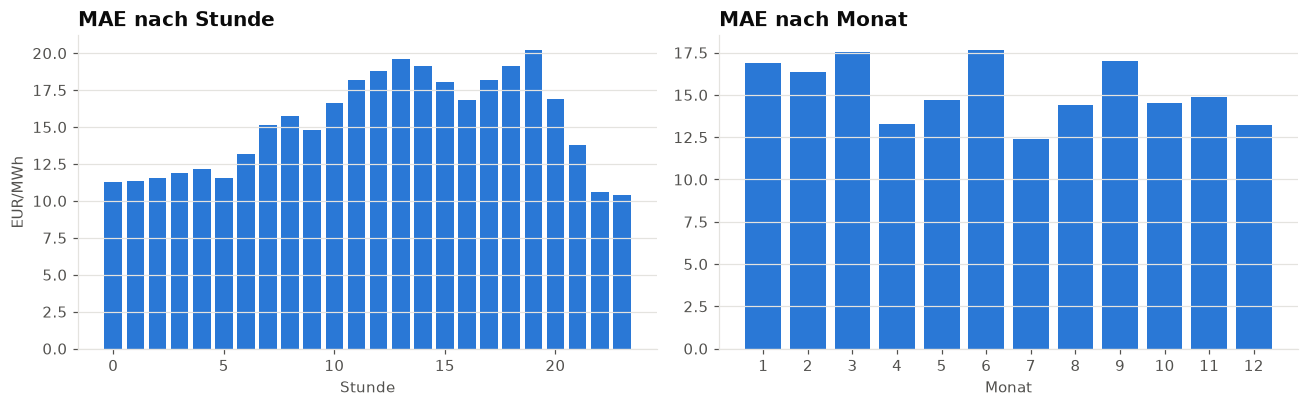

In [6]:
err = test.assign(abs_error=(predictions["XGBoost"] - test["price"]).abs())
by_hour = err.groupby("hour")["abs_error"].mean()
by_month = err.groupby("month")["abs_error"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(by_hour.index, by_hour.values, color=COLORS["blue"])
axes[0].set_title("MAE nach Stunde"); axes[0].set_xlabel("Stunde"); axes[0].set_ylabel("EUR/MWh")
axes[1].bar(by_month.index, by_month.values, color=COLORS["blue"])
axes[1].set_title("MAE nach Monat"); axes[1].set_xlabel("Monat"); axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

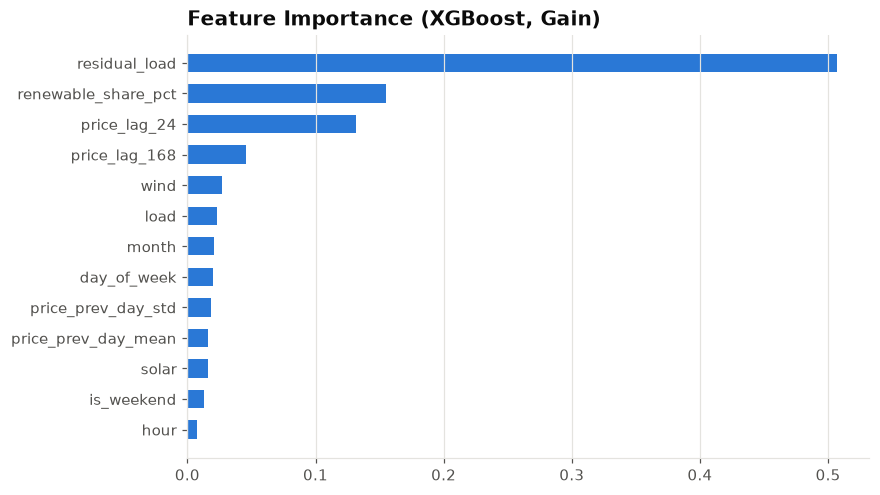

In [7]:
importance = pd.Series(xgb.feature_importances_, index=MODEL_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=COLORS["blue"], height=0.6)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Feature Importance (XGBoost, Gain)")
save(fig, "feature_importance")
plt.show()

## Fazit

* XGBoost reduziert den MAE gegenüber der naiven Vortagsprognose um rund 40 %.
* Die **Residuallast** ist mit Abstand das wichtigste Feature – das bestätigt die
  Merit-Order-Logik aus der EDA. Danach folgen EE-Anteil und Vortagespreis.
* Die größten Fehler entstehen in den Abendstunden und in den Wintermonaten, wenn
  Preisspitzen durch Knappheit (z. B. Dunkelflauten) auftreten.
* Die lineare Regression ist nur knapp schlechter. Der Großteil der Erklärungskraft
  steckt also in guten, fachlich motivierten Features.

**Grenzen und nächste Schritte**

* Ist-Werte statt echter Wind-/Solar-/Lastprognosen → in der Praxis größerer Fehler.
  Nächster Schritt: Prognosedaten der Übertragungsnetzbetreiber (ENTSO-E) nutzen.
* Brennstoff- und CO₂-Preise (Gas, EUA) fehlen als Features; sie bestimmen das
  Preisniveau konventioneller Kraftwerke.
* Feiertage sind nicht berücksichtigt (z. B. über das Paket `holidays`).
* Rollierende Validierung (Walk-Forward) statt eines einzelnen Testjahres.